# Comparing stochastic MLP training strategies

This notebook replays the [scikit-learn gallery example](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/neural_networks/plot_mlp_training_curves.py) at revision `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

Seven training strategies run on Iris, Digits, Circles and Moons. Each model
uses seed 0, the default 100-unit ReLU hidden layer and the gallery budget
of 15 epochs for Digits or 400 epochs for the other datasets. Both sides
scale their own inputs with MinMaxScaler. The datasets are available offline.

Gallery configuration adapted from the scikit-learn developers (BSD-3-Clause).
See the [third-party notices](../../families/neural_network/THIRD_PARTY_NOTICES).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("neural_network/plot_mlp_training_curves")

## scikit-learn reference

Load the pinned MLP estimator, activations, losses and optimizers through the
family's parity harness. Capture each model's full loss curve and training predictions.

In [2]:
import runpy
import warnings

import numpy as np
from matplotlib import pyplot as plt
from sklearn import datasets
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import MinMaxScaler

reference = runpy.run_path(str(ROOT / "families/neural_network/tests/mlp_parity.py"))["load_reference"]()
dataset_names = ("Iris", "Digits", "Circles", "Moons")
data = (
    datasets.load_iris(return_X_y=True),
    datasets.load_digits(return_X_y=True),
    datasets.make_circles(noise=0.2, factor=0.5, random_state=1),
    datasets.make_moons(noise=0.3, random_state=0),
)
strategies = [
    (f"{schedule} · {label}", dict(
        solver="sgd", learning_rate=schedule, learning_rate_init=0.2,
        momentum=momentum, nesterovs_momentum=nesterov,
    ))
    for schedule in ("constant", "invscaling")
    for label, momentum, nesterov in (
        ("no momentum", 0, True), ("momentum", 0.9, False), ("Nesterov", 0.9, True),
    )
]
strategies.append(("Adam", dict(solver="adam", learning_rate_init=0.01)))

scaled, runs = [], []
# Epoch-budget convergence warnings are expected for some gallery settings.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for k, (X, y) in enumerate(data):
        nb.share(**{f"X{k}": X.astype(np.float64), f"y{k}": y.astype(np.int64)})
        X = MinMaxScaler().fit_transform(X)
        scaled.append(X)
        max_iter = 15 if k == 1 else 400
        for _, params in strategies:
            model = reference.MLPClassifier(random_state=0, max_iter=max_iter, **params)
            model.fit(X, y)
            runs.append((model.loss_curve_, model.n_iter_, model.loss_,
                         model.score(X, y), model.predict(X)))

## Moxie replay

The Mojo cell uses the same seven settings and trains through the public MLP
API. It reads learned attributes through methods. For stochastic fits,
`loss_curve_()` returns a populated `Optional[List[Float64]]`.

In [3]:
%%mojo training_curves
from numojo import NDArray
from moxie.neural_network import MLPClassifier
from moxie.preprocessing import MinMaxScaler
from moxie_nb_io import load, save, save_floats, save_ints


def record_fit(
    X: NDArray[DType.float64],
    y: NDArray[DType.int64],
    key: String,
    max_iter: Int,
    *,
    solver: String = "sgd",
    schedule: String = "constant",
    rate: Float64 = 0.2,
    momentum: Float64 = 0.9,
    nesterov: Bool = True,
) raises:
    var model = MLPClassifier(
        solver=solver,
        learning_rate=schedule,
        learning_rate_init=rate,
        momentum=momentum,
        nesterovs_momentum=nesterov,
        random_state=0,
        max_iter=max_iter,
    )
    _ = model.fit(X, y)
    var curve = model.loss_curve_()
    if not curve:
        raise Error("Expected a stochastic loss curve")
    save_floats("curve" + key, curve.value())
    save_ints("epochs" + key, [model.n_iter_()])
    save_floats("metrics" + key, [model.loss_(), model.score(X, y)])
    save("labels" + key, model.predict(X))


def main() raises:
    var schedules: List[String] = ["constant", "invscaling"]
    for k in range(4):
        var dataset = String(k)
        var scaler = MinMaxScaler()
        var X = scaler.fit_transform(load("X" + dataset))
        var y = load[DType.int64]("y" + dataset)
        save("scaled" + dataset, X)
        var max_iter = 15 if k == 1 else 400
        for s in range(len(schedules)):
            var offset = k * 7 + s * 3
            record_fit(
                X,
                y,
                String(offset),
                max_iter,
                schedule=schedules[s],
                momentum=0,
            )
            record_fit(
                X,
                y,
                String(offset + 1),
                max_iter,
                schedule=schedules[s],
                nesterov=False,
            )
            record_fit(
                X, y, String(offset + 2), max_iter, schedule=schedules[s]
            )
        record_fit(X, y, String(k * 7 + 6), max_iter, solver="adam", rate=0.01)

## Loss curves and parity

Each chart overlays Moxie markers on the scikit-learn lines. The checks compare
the entire loss history and final loss within Float64 tolerances, and require
the same stopping epoch, training labels and accuracy.

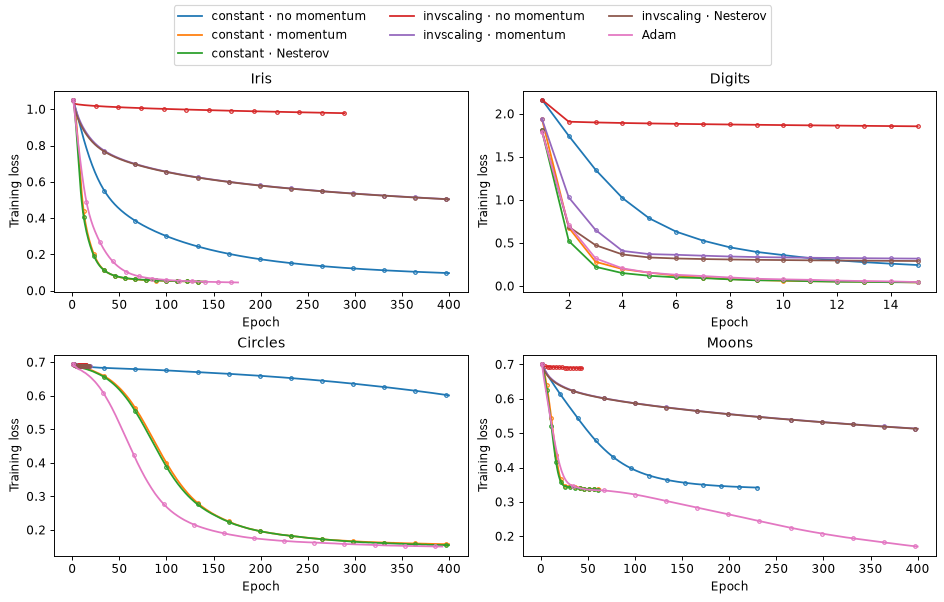

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Iris scaled features,PASS,"(150, 4)","(150, 4)",0,0,"rtol=2e-15, atol=2e-15",,Float64 scaling arithmetic
Iris · constant · no momentum loss curve,PASS,"(400,)","(400,)",1.11e-15,1.57e-15,"rtol=2e-12, atol=2e-12",,Float64 matrix products and optimizer updates over repeated batches
Iris · constant · no momentum final loss,PASS,(),(),1.53e-16,1.57e-15,"rtol=2e-12, atol=2e-12",,Float64 matrix products and optimizer updates over repeated batches
Iris · constant · no momentum stopping epoch,PASS,"(1,)","(1,)",,,exact,0 mismatches,
Iris · constant · no momentum training labels,PASS,"(150,)","(150,)",,,exact,0 mismatches,
Iris · constant · no momentum training accuracy,PASS,(),(),,,exact,0 mismatches,
Iris · constant · momentum loss curve,PASS,"(139,)","(139,)",1.11e-15,1.05e-15,"rtol=2e-12, atol=2e-12",,Float64 matrix products and optimizer updates over repeated batches
Iris · constant · momentum final loss,PASS,(),(),1.39e-17,2.8e-16,"rtol=2e-12, atol=2e-12",,Float64 matrix products and optimizer updates over repeated batches
Iris · constant · momentum stopping epoch,PASS,"(1,)","(1,)",,,exact,0 mismatches,
Iris · constant · momentum training labels,PASS,"(150,)","(150,)",,,exact,0 mismatches,


In [4]:
native = nb.results["training_curves"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), dpi=85, layout="constrained")
for k, (name, ax) in enumerate(zip(dataset_names, axes.flat)):
    nb.compare(f"{name} scaled features", scaled[k], native[f"scaled{k}"],
               rtol=2e-15, atol=2e-15, reason="Float64 scaling arithmetic")
    ax.set(title=name, xlabel="Epoch", ylabel="Training loss")
    for s, (label, _) in enumerate(strategies):
        panel = k * len(strategies) + s
        curve, epochs, loss, score, labels = runs[panel]
        native_curve = native[f"curve{panel}"]
        name_and_strategy = f"{name} · {label}"
        loss_tolerance = dict(rtol=2e-12, atol=2e-12,
                              reason="Float64 matrix products and optimizer updates over repeated batches")
        nb.compare(f"{name_and_strategy} loss curve", curve, native_curve, **loss_tolerance)
        nb.compare(f"{name_and_strategy} final loss", loss, native[f"metrics{panel}"][0],
                   **loss_tolerance)
        nb.compare(f"{name_and_strategy} stopping epoch", [epochs], native[f"epochs{panel}"], exact=True)
        nb.compare(f"{name_and_strategy} training labels", labels, native[f"labels{panel}"], exact=True)
        nb.compare(f"{name_and_strategy} training accuracy", score, native[f"metrics{panel}"][1], exact=True)

        line, = ax.plot(np.arange(1, epochs + 1), curve, label=label)
        ax.plot(np.arange(1, len(native_curve) + 1), native_curve, marker="o", markersize=3,
                linestyle="none", markevery=max(1, len(native_curve) // 12), markerfacecolor="none",
                color=line.get_color())

fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="outside upper center", ncol=3)
plt.show()
nb.report()
nb.assert_parity()